## tl;dr

The leakage-safe hurdle model is ready to become an input to prop-model retraining, but remains disabled for live use. On the 2025-26 holdout it reached availability AUC **0.886**, reduced conditional-minutes MAE from **5.028** to **4.788**, reduced fixed-gate all-candidate MAE from **6.157** to **5.903**, and reduced expected-minutes RMSE from **9.878** to **8.728**.

## Context & Methods

The source is `data/nba_data.csv`. A pregame candidate exists only after two prior same-team appearances, with recent rotation minutes of at least eight and no more than 45 days since the last appearance. Features are updated only after each target game is scored. Model families are selected on four expanding date folds in the first two seasons; 2025-26 is excluded from fitting and selection.

### Key Assumptions

Historical candidates are inferred from game logs because no historical roster/transaction feed exists. The likely-prop-pool cut is a proxy, not an archived PrizePicks board.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
summary = json.loads((ROOT / 'output/availability_minutes_validation_summary.json').read_text())
audit = json.loads((ROOT / 'output/availability_minutes_validation_audit.json').read_text())
calibration = pd.read_csv(ROOT / 'output/availability_minutes_calibration.csv')
subgroups = pd.read_csv(ROOT / 'output/availability_minutes_holdout_subgroups.csv')
folds = pd.read_csv(ROOT / 'output/availability_minutes_walk_forward.csv')
oof = pd.read_csv(ROOT / 'data/availability_minutes_oof_predictions.csv', low_memory=False)
print(audit['overall_assessment'])
print(summary['data_quality'])

ready_for_prop_retraining
{'source_rows': 81065, 'source_player_game_duplicates': 0, 'source_date_min': '2023-10-24', 'source_date_max': '2026-05-18', 'source_seasons': ['2023-24', '2024-25', '2025-26'], 'candidate_rows': 98217, 'candidate_unique_dates': 508, 'candidate_unique_players': 762, 'candidate_duplicate_keys': 0, 'candidate_availability_rate': 0.7281326043352984, 'candidate_feature_null_cells': 0, 'development_rows': 62773, 'holdout_rows': 35444, 'holdout_season': '2025-26', 'holdout_start': '2025-10-24', 'holdout_end': '2026-05-18', 'oof_rows': 74965, 'oof_start': '2024-03-08', 'oof_end': '2026-05-18', 'oof_same_or_future_train_dates': 0}


## Data

The checks below verify the saved feature grain and strict chronology of the reusable out-of-fold table.

In [2]:
oof['game_date'] = pd.to_datetime(oof['game_date'])
oof['model_train_end'] = pd.to_datetime(oof['model_train_end'])
assert not oof.duplicated(['game_id', 'team', 'player_id']).any()
assert (oof['model_train_end'] < oof['game_date']).all()
assert audit['checks']['candidate_key_duplicates'] == 0
assert audit['checks']['candidate_null_feature_cells'] == 0
pd.DataFrame([audit['checks']]).T.rename(columns={0: 'value'})

,value
candidate_key_duplicates,0.000000
candidate_null_feature_cells,0.000000
oof_key_duplicates,0.000000
oof_chronology_failures,0.000000
holdout_join_rows,35444.000000
holdout_expected_rows,35444.000000
calibration_max_absolute_decile_gap,0.022683


## Results

Every reported improvement is paired against a pregame-only baseline on the same player/team/game rows. Calibration is close to the diagonal, including in the low-probability region that matters most for avoiding inactive-player props.

In [3]:
display_columns = [
    'subgroup', 'rows', 'availability_brier', 'brier_improvement',
    'conditional_minutes_mae', 'conditional_mae_improvement',
    'hard_gated_minutes_mae', 'hard_mae_improvement',
    'soft_expected_minutes_rmse', 'soft_rmse_improvement',
]
subgroups[display_columns].round(4)

,subgroup,rows,availability_brier,brier_improvement,conditional_minutes_mae,conditional_mae_improvement,hard_gated_minutes_mae,hard_mae_improvement,soft_expected_minutes_rmse,soft_rmse_improvement
0,all_holdout_candidates,35444,0.1115,0.0347,4.7877,0.2398,5.9027,0.2545,8.7283,1.1496
1,first_half,18518,0.1024,0.0370,4.5969,0.2312,5.6648,0.2596,8.4068,1.0817
2,second_half,16926,0.1214,0.0322,5.0156,0.2501,6.1630,0.2490,9.0671,1.2202
3,rotation_15_plus,26977,0.0939,0.0352,4.6121,0.2051,6.2221,0.2990,9.2317,1.2579
4,likely_prop_pool_proxy,19398,0.0786,0.0158,4.5985,0.1592,6.4491,0.2828,9.1808,1.1111
5,model_probability_080_plus,21946,0.0700,0.0196,4.6094,0.1944,6.1349,0.1275,8.7768,0.3703


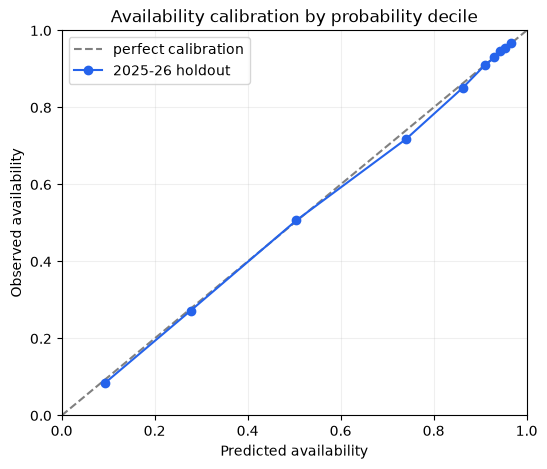

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='perfect calibration')
ax.plot(calibration['predicted_availability'], calibration['actual_availability'], marker='o', color='#2563eb', label='2025-26 holdout')
ax.set(xlabel='Predicted availability', ylabel='Observed availability', title='Availability calibration by probability decile')
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(); ax.grid(alpha=.2)
plt.show()

## Takeaways

1. Use `data/availability_minutes_oof_predictions.csv` for historical prop-model training; it has a strict pre-target training cutoff.
2. Carry availability probability and conditional minutes as separate features. Use the fixed 0.50 gate only where a point decision is required.
3. Keep `models/availability_minutes_model.pkl` out of live production until the retrained prop stack clears its own chronological holdout and same-prop baselines.